# 03 · Analysis

Reads `results/` only, no training here.
1. Overview of all systems
2. Overfitting: where does it start?
3. Low-rank compression: the rank sweep
4. Bayesian comparison with a ROPE

In [1]:
# Setup: make the course code (part1) and our code (src) importable.
# Run notebooks from this folder (JupyterLab / VS Code do this by default).
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve().parents[1]
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from part1 import analysis
from src import config, report, results_io

## 1 · Overview

In [3]:
scores = results_io.fold_scores()
pd.DataFrame({n: {"mean acc": np.mean(s), "std": np.std(s)} for n, s in scores.items()}).T.sort_values("mean acc", ascending=False)

,mean acc,std
mlp__indicator,0.552370,0.008164
mlp__bow,0.550148,0.006325
mlp__tfidf,0.543172,0.007117
loglin__indicator,0.535405,0.006015
deeplowrank__bow,0.525591,0.008477
deeplowrank__indicator,0.525503,0.009993
loglin__tfidf,0.521586,0.008506
loglin__bow,0.510760,0.011015
deeplowrank__tfidf,0.501628,0.007414


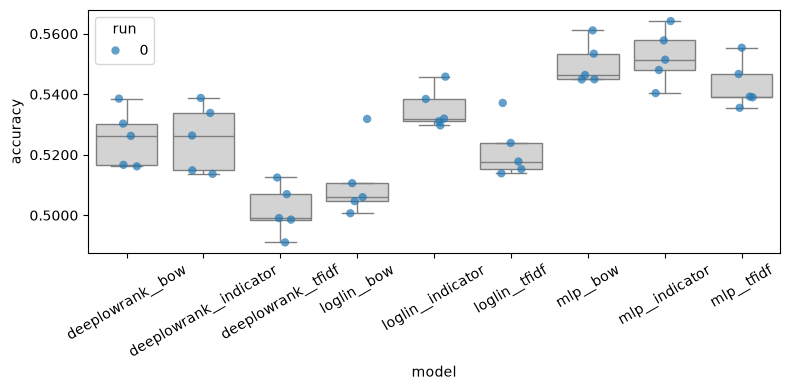

In [4]:
df = analysis.make_data_frame(results_io.for_dataframe())
analysis.plot_box_and_points(df, metric="accuracy")

## 2 · Overfitting

The neural models train for 10 epochs without early stopping, so we can see what happens after the best epoch.
Overfitting starts where validation accuracy stops rising and goes down, while training accuracy keeps going up.
The CV scores above use the best epoch (lowest validation loss).

The course MLP does not save its per-epoch numbers, so we read them from the training log in `02_experiments`.

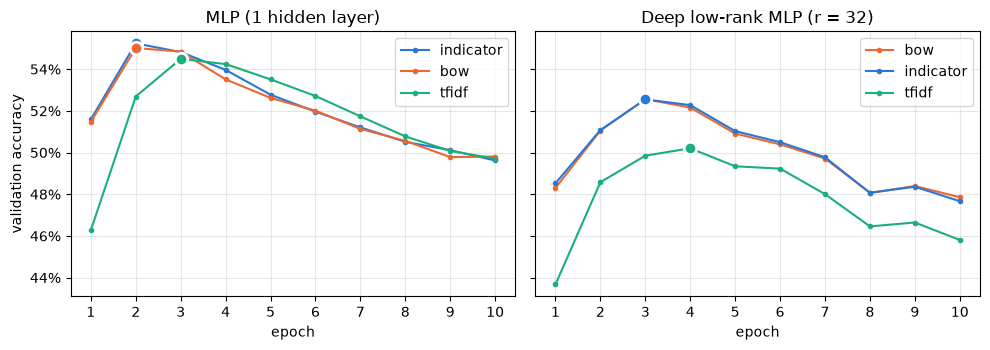

In [5]:
mlp_curves = report.course_mlp_curves_from_log()
deep_curves = {n: results_io.load(n)["curves"] for n in scores if n.startswith("deeplowrank__")}

fig = report.plot_val_accuracy({"MLP (1 hidden layer)": {n.split("__")[1]: c for n, c in mlp_curves.items()},
                                "Deep low-rank MLP (r = 32)": {n.split("__")[1]: c for n, c in deep_curves.items()}})
report.save(fig, "val_accuracy_overfitting")
plt.show()

In [6]:
rows = {}
for name, curves in {**mlp_curves, **deep_curves}.items():
    v = report.val_curve(curves).mean(0)
    t = np.array([[ep["train_metrics"]["accuracy"] for ep in curves[f]] for f in curves]).mean(0)
    rows[name] = {"best epoch": v.argmax() + 1, "best val acc": v.max(), "val acc epoch 10": v[-1],
                  "train acc epoch 10": t[-1]}
pd.DataFrame(rows).T

,best epoch,best val acc,val acc epoch 10,train acc epoch 10
mlp__indicator,2.0,0.552360,0.496200,0.966720
mlp__bow,2.0,0.550140,0.498080,0.967100
mlp__tfidf,3.0,0.544900,0.497060,0.930920
deeplowrank__bow,3.0,0.525591,0.478590,0.807535
deeplowrank__indicator,3.0,0.525503,0.476676,0.809323
deeplowrank__tfidf,4.0,0.502046,0.458082,0.753801


**Conclusion.** The MLP overfits after epoch 2, the deep low-rank model after epoch 3 (with TF-IDF both one epoch later).
After that, training accuracy keeps climbing (to ~97 % for the MLP) while validation accuracy drops by about 5 points by epoch 10.
So training longer only hurts; early stopping after 2–3 epochs would be enough.

## 3 · Low-rank compression

Our deep MLP factorises each weight matrix as W = A·B with rank r. A lower rank means fewer parameters.
How much accuracy do we lose, and does a low rank reduce overfitting?

In [7]:
sweep = report.load_sweep()
sweep[["representation", "rank", "params", "cv acc", "cv std"]]

,representation,rank,params,cv acc,cv std
0,bow,4,55388,0.491176,0.007418
1,bow,8,102556,0.507900,0.005806
2,bow,16,196892,0.517273,0.006427
3,bow,32,385564,0.525591,0.008477
4,bow,64,762908,0.528364,0.008993
5,bow,128,1517596,0.528385,0.010547
6,bow,full,2764828,0.539388,0.010600
7,indicator,4,55388,0.490538,0.005788
8,indicator,8,102556,0.510012,0.005231
9,indicator,16,196892,0.516569,0.008277


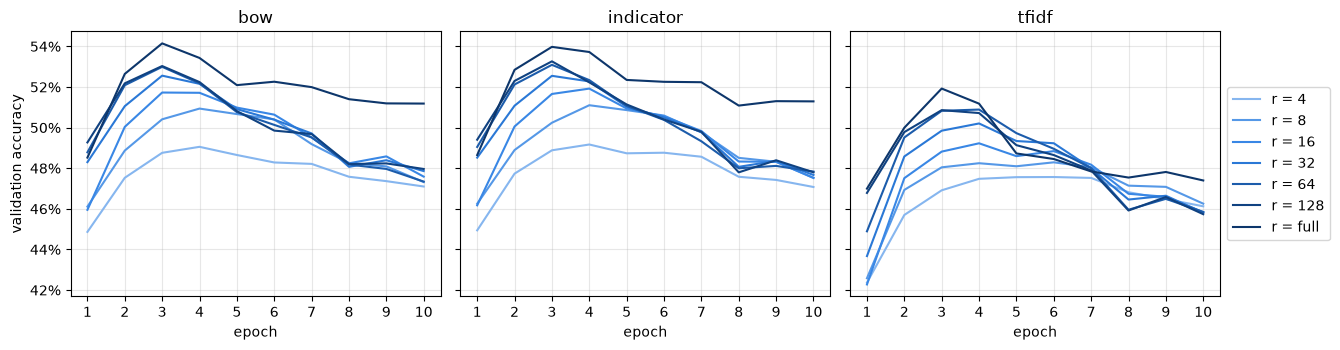

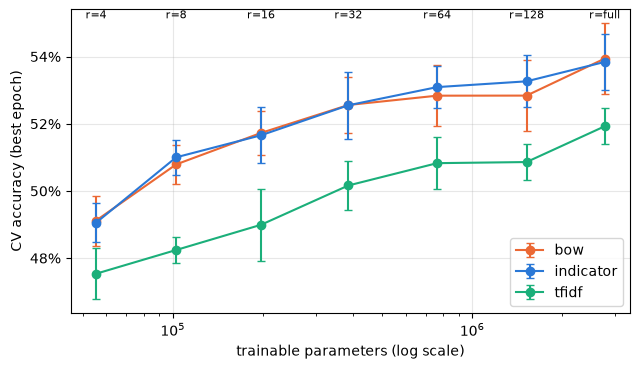

In [8]:
fig = report.plot_rank_curves(sweep)
report.save(fig, "rank_val_accuracy_curves")
plt.show()

fig = report.plot_compression_tradeoff(sweep)
report.save(fig, "rank_compression_tradeoff")
plt.show()

**Conclusion.** Accuracy goes up steadily with the rank (about 49 % at r = 4 to 54 % at full rank), so compression always costs some accuracy.
r = 64–128 gets close to full rank with 28–55 % of the parameters. Every rank starts to overfit around epoch 3,
but the low ranks drop less after their peak: the rank limits how much the model can memorise.
Even at full rank, the deep model stays below the simple one-hidden-layer MLP.

## 4 · Bayesian comparison with ROPE

ROPE = the smallest difference we would care about in practice.
**Our choice:** 0.01 (1 accuracy point), because the fold-to-fold standard deviation of our systems is already about 0.6–1 point,
so smaller differences are within noise.

mlp__bow vs mlp__indicator: P(A better, equivalent, B better) = [0.006 0.969 0.025]


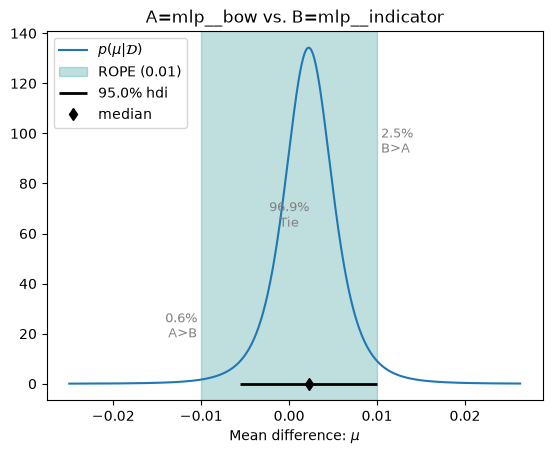

loglin__indicator vs mlp__indicator: P(A better, equivalent, B better) = [0.    0.023 0.976]


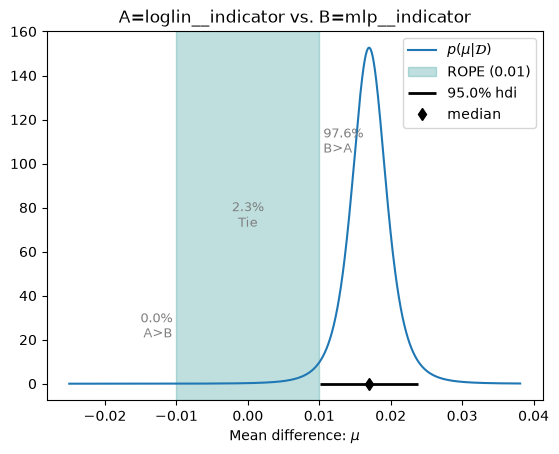

deeplowrank__indicator vs mlp__indicator: P(A better, equivalent, B better) = [0.    0.002 0.998]


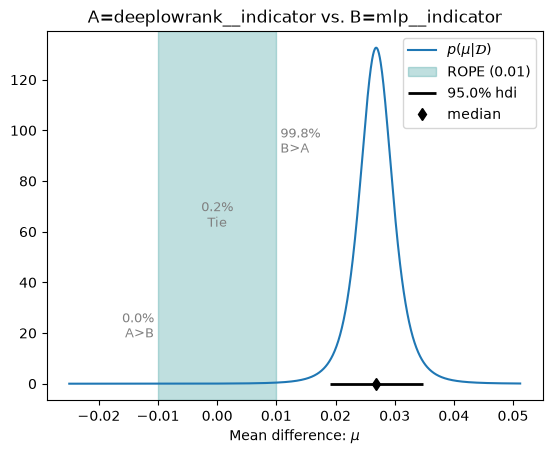

In [9]:
ROPE = 0.01

pairs = [("mlp__bow", "mlp__indicator"),                 # best two
         ("loglin__indicator", "mlp__indicator"),        # log-linear vs MLP
         ("deeplowrank__indicator", "mlp__indicator")]   # ours vs MLP
for a, b in pairs:
    test = analysis.BenavoliCorrelatedT(scores[a], scores[b], names=[a, b])
    print(f"{a} vs {b}: P(A better, equivalent, B better) =", np.round(test.probs(ROPE), 3))
    test.plot(ROPE)
    plt.show()

**Conclusion.** MLP with indicators and MLP with bag-of-words are practically equivalent.
The MLP is better than the log-linear model and clearly better than our deep low-rank MLP.
Best model: **MLP (one hidden layer) with token indicators, 55.2 % accuracy**.